# 04 training evaluation
Dataset-dependent analysis is pending. No dataset is loaded automatically.

In [1]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import pandas as pd

import classification
from classification.model_config import MODEL_CONFIGS
from classification.training import create_models, create_cross_validation, compare_models, tune_model

## Baseline and evaluation metrics
Record observations and justify decisions here after selecting the dataset.

In [3]:
df = pd.read_csv("../data/raw/student_mental_health.csv")

In [4]:
from classification.model_config import RANDOM_STATE
from sklearn.model_selection import train_test_split
from classification.preprocessing import remove_invalid_targets

cleaned_df = remove_invalid_targets(df)
X = cleaned_df.drop(columns=["Student_ID", "Mental_Health_Risk"])

risk_codes = {"Low": 0, "Medium": 1, "High": 2}
y = cleaned_df["Mental_Health_Risk"].map(risk_codes)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)


models = create_models(MODEL_CONFIGS)
cv = create_cross_validation()
result = compare_models(models, X_train, y_train, cv)


In [5]:
display(result)

,model,mean_score,std_score,mean_fit_time
0,logistic_regression,0.757708,0.020192,0.134194
3,svc,0.721404,0.020486,0.134247
2,random_forest,0.684276,0.021928,0.501545
1,decision_tree,0.571389,0.007163,0.084001


In [6]:

best = result.iloc[0]["model"]
search = tune_model(models[best], MODEL_CONFIGS[best]["search_space"],
                         X_train,
                         y_train,
                         cv,
                         method="grid")

In [7]:
from pathlib import Path
import joblib

model_path = Path("../reports/models/champion.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(search.best_estimator_, model_path)
print(model_path.resolve())

/workspace/reports/models/champion.joblib


Accuracy: 0.7675
              precision    recall  f1-score   support

         Low      0.831     0.780     0.805       132
      Medium      0.645     0.674     0.659       132
        High      0.833     0.846     0.839       136

    accuracy                          0.767       400
   macro avg      0.770     0.767     0.768       400
weighted avg      0.770     0.767     0.769       400

Matrice de confusion (lignes=vrai, colonnes=prédit):


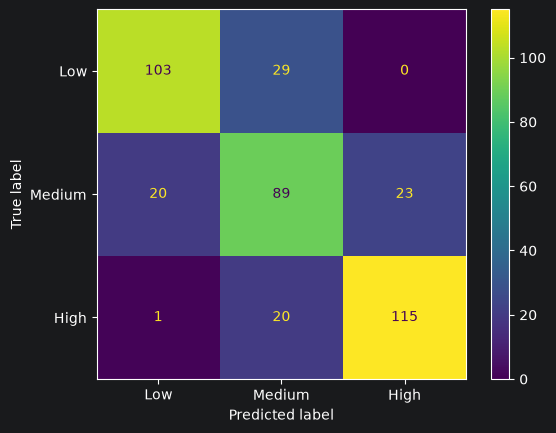

ROC-AUC macro OvR: 0.9169051411835653


In [20]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

model = joblib.load(model_path)
y_pred = model.predict(X_test)
labels = [0, 1, 2]
names = ["Low", "Medium", "High"]

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, labels=labels, target_names=names, digits=3))
print("Matrice de confusion (lignes=vrai, colonnes=prédit):")
conf_matrix = confusion_matrix(y_test, y_pred, labels=labels)
ConfusionMatrixDisplay(confusion_matrix= conf_matrix, display_labels = names).plot()
plt.show()

print("ROC-AUC macro OvR:", roc_auc_score(
    y_test, model.predict_proba(X_test), labels=labels,
    multi_class="ovr", average="macro"
))